# 06 — Which inputs carry signal? Random forest, lasso and drop-one tests

**Goal.** The main model used nine inputs known at report time (`features.py`). Do all
of them help, or do some only add noise? Three methods, which fail in different ways,
so agreement between them is the evidence:

1. **Random forest permutation importance.** Fit a random forest, then shuffle one
   input in the test year and measure how much the ranking (PR-AUC) gets worse.
2. **Lasso path.** An L1-penalised logistic regression sends weak coefficients to
   exactly zero. As the penalty is relaxed, strong inputs enter first and weak ones
   last. Ridge is shown for contrast: it shrinks coefficients but never to zero, so it
   cannot be used to drop inputs.
3. **Drop-one test on the chosen model.** Rerun the gradient-boosting backtest without
   each input, and compare with the full model on the same resampled days. This is the
   test that decides: the first two describe *a* model, this one the model we use.

Only the training years (2019-2023) and the rolling folds of `backtest.py` are used.
The 2024-25 holdout has been run once and is not touched again.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# The notebook lives in code/exploration/; the project modules live in code/.
sys.path.insert(0, str(Path.cwd().parent))
import config
from cleaning.load import load_incidents
from modeling.backtest import FOLDS, compare_predictions, run_backtest
from modeling.costs import sample_weights
from modeling.features import CATEGORICAL_FEATURES, MAIN_FEATURES, NO_SIGNAL_FEATURES, build_features
from modeling.target import add_targets, model_population

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Load train incidents and their inputs

Same population, label (`y_major`) and sample weights as the main model (no safety
weight since Decision 9). `door_involved` is the raw door flag (Decision 9).

In [2]:
labelled = add_targets(model_population(load_incidents()))
# The nine inputs the main model had before this notebook (Decision 8 dropped two).
NINE_INPUTS = MAIN_FEATURES + NO_SIGNAL_FEATURES
X = build_features(labelled)[NINE_INPUTS]
y = labelled["y_major"]
weight = sample_weights(labelled)
year = labelled["service_date"].dt.year
FLAGS = [column for column in NINE_INPUTS if column not in CATEGORICAL_FEATURES]


def one_hot_encoder():
    """Every category level becomes a 0/1 column; the yes/no flags pass through."""
    return ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ("flags", "passthrough", FLAGS),
    ])


def input_of(encoded_name):
    """Encoded column (e.g. 'categories__symptom_Divers') -> the input it comes from."""
    column = encoded_name.split("__", 1)[1]
    return next(feature for feature in NINE_INPUTS if column.startswith(feature))

## 2. Random forest importance

**Why permutation, not the built-in importance.** A forest's built-in ("impurity")
importance counts how much each input is used to split the training data. It favours
inputs with many levels, because they offer more ways to split, even when those splits
are noise; and it is measured on the training data. Permutation importance is measured
on the test year: shuffle one input, so its link with the outcome is broken, and see
how much worse the ranking becomes. An input that only fits noise loses nothing.

The forest is fitted per fold on the training years (small leaves of at least 50
incidents, so it cannot memorise single incidents), and each input is shuffled 10
times in the test year.

In [3]:
def random_forest():
    return Pipeline([
        ("encode", one_hot_encoder()),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=config.RANDOM_SEED)),
    ])


permutation_drop, impurity = {}, {}
for test_year, (first_year, last_year) in FOLDS.items():
    train, test = year.between(first_year, last_year), year == test_year
    forest = random_forest().fit(X[train], y[train], model__sample_weight=weight[train])
    shuffled = permutation_importance(
        forest, X[test], y[test], scoring="average_precision",
        n_repeats=10, random_state=config.RANDOM_SEED, n_jobs=-1)
    permutation_drop[test_year] = pd.Series(shuffled.importances_mean, index=NINE_INPUTS)
    # Built-in importance, summed over the 0/1 columns of each input.
    encoded = forest.named_steps["encode"].get_feature_names_out()
    impurity[test_year] = pd.Series(
        forest.named_steps["model"].feature_importances_, index=encoded).groupby(input_of).sum()
    print(f"Fold {test_year}: forest PR-AUC "
          f"{average_precision_score(y[test], forest.predict_proba(X[test])[:, 1]):.3f}")

permutation_drop = pd.DataFrame(permutation_drop)
importance = pd.DataFrame({
    "PR-AUC lost when shuffled (mean of folds)": permutation_drop.mean(axis=1),
    "smallest over folds": permutation_drop.min(axis=1),
    "largest over folds": permutation_drop.max(axis=1),
    "built-in importance (mean of folds)": pd.DataFrame(impurity).mean(axis=1),
}).sort_values("PR-AUC lost when shuffled (mean of folds)", ascending=False)
importance.round(4)

Fold 2021: forest PR-AUC 0.214


Fold 2022: forest PR-AUC 0.195


Fold 2023: forest PR-AUC 0.231


,PR-AUC lost when shuffled (mean of folds),smallest over folds,largest over folds,built-in importance (mean of folds)
symptom,0.1481,0.1332,0.1771,0.5149
door_involved,0.0731,0.0284,0.1091,0.0784
at_terminal,0.0724,0.0493,0.0931,0.0711
emergency_brake,0.0589,0.0457,0.0802,0.0424
location_kind,0.0219,0.0166,0.0288,0.0811
line_group,0.0162,0.0101,0.0213,0.1058
time_of_day,0.0089,0.0009,0.0228,0.0720
is_weekend,-0.0005,-0.0015,0.0008,0.0155
at_transfer_station,-0.0050,-0.0109,-0.0015,0.0189


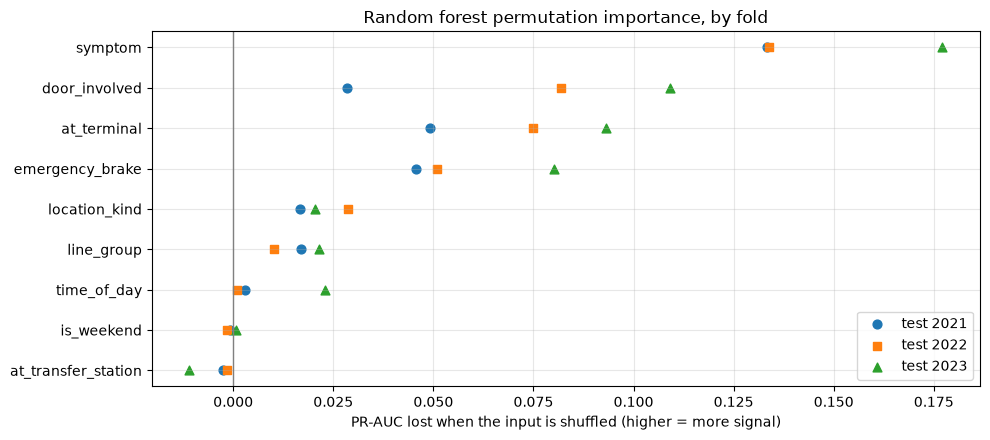

In [4]:
# Plot: PR-AUC lost when each input is shuffled, one dot per fold.
order = importance.index[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
for test_year, marker in zip(FOLDS, ["o", "s", "^"]):
    ax.scatter(permutation_drop.loc[order, test_year], range(len(order)),
               marker=marker, s=40, label=f"test {test_year}")
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("PR-AUC lost when the input is shuffled (higher = more signal)")
ax.set_title("Random forest permutation importance, by fold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Reading.** Symptom carries most of the signal, then the door flag and the terminal
flag. Weekend and transfer station lose nothing when shuffled: their dots sit on zero,
and shuffling the transfer flag even helps a little in every fold, which is what noise
looks like. The built-in importance ranks line and location higher and the emergency brake
lower than permutation does: those inputs have more levels to split on.

## 3. Lasso path (and ridge for contrast)

**Intuition.** The lasso adds a penalty of λ × |coefficient| to the fit. Near zero that
penalty costs the same for every small step, so a coefficient whose evidence is weaker
than λ is not worth paying for and is set to exactly zero. Start with a huge penalty
(every coefficient zero) and relax it: inputs enter in order of how much evidence they
carry. Ridge uses λ × coefficient² instead, whose cost vanishes near zero, so it always
keeps a little of every coefficient: it shrinks, it never selects.

`C` below is 1/λ (scikit-learn's convention): small C = strong penalty. The fit uses
all training years, 2019-2023, with the same weights. Every column is 0/1, so the
coefficients are on the same scale and no standardising is needed.

One caveat: the lasso works on one-hot *levels*, not whole inputs, so "an input enters"
means "its first level gets a non-zero coefficient". A group lasso would treat the
levels of an input together; scikit-learn does not have one, and for a ranking of
inputs the first entry is enough.

In [5]:
before_holdout = year <= 2023
encoder = one_hot_encoder().fit(X[before_holdout])
encoded = encoder.transform(X[before_holdout]).astype(float)
encoded_names = encoder.get_feature_names_out()
owners = [input_of(name) for name in encoded_names]

penalties = np.logspace(-3.5, 1, 19)          # C from 0.0003 (strong) to 10 (weak)


def coefficient_path(l1_ratio):
    """Coefficients at each C; l1_ratio=1 is the lasso, 0 is ridge."""
    path = {}
    for C in penalties:
        fit = LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear", max_iter=5000)
        fit.fit(encoded, y[before_holdout], sample_weight=weight[before_holdout])
        path[C] = pd.Series(fit.coef_[0], index=encoded_names)
    return pd.DataFrame(path)


lasso_path = coefficient_path(l1_ratio=1.0)
ridge_path = coefficient_path(l1_ratio=0.0)

# For each input: the strongest penalty (smallest C) at which any of its levels is non-zero.
in_model = (lasso_path.abs() > 0).groupby(owners).any()
entry = pd.DataFrame({
    "enters the lasso at C =": in_model.idxmax(axis=1),
    "levels kept at C = 0.01": (lasso_path[penalties[9]].abs() > 0).groupby(owners).sum(),
    "levels in total": pd.Series(owners).value_counts(),
}).sort_values("enters the lasso at C =")
entry

,enters the lasso at C =,levels kept at C = 0.01,levels in total
location_kind,0.003162,2,6
symptom,0.003162,4,8
at_terminal,0.010000,1,1
line_group,0.010000,3,6
door_involved,0.017783,1,1
time_of_day,0.017783,2,6
emergency_brake,0.031623,1,1
is_weekend,0.562341,0,1
at_transfer_station,1.000000,0,1


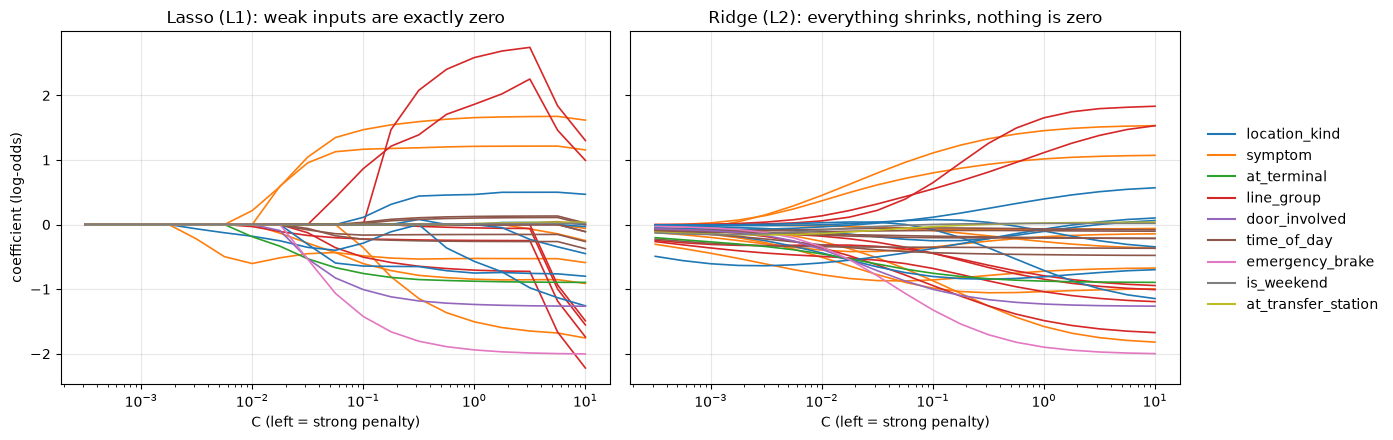

In [6]:
# Plot: lasso and ridge paths, one line per encoded column, coloured by input.
inputs_in_entry_order = list(entry.index)
colors = dict(zip(inputs_in_entry_order, plt.get_cmap("tab10").colors))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, path, title in [(axes[0], lasso_path, "Lasso (L1): weak inputs are exactly zero"),
                        (axes[1], ridge_path, "Ridge (L2): everything shrinks, nothing is zero")]:
    for name, owner in zip(encoded_names, owners):
        ax.plot(penalties, path.loc[name], color=colors[owner], linewidth=1.2)
    ax.set_xscale("log")
    ax.set_xlabel("C (left = strong penalty)")
    ax.set_title(title)
axes[0].set_ylabel("coefficient (log-odds)")
handles = [plt.Line2D([], [], color=colors[name], label=name) for name in inputs_in_entry_order]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout()
plt.show()

In [7]:
# Ridge never selects: count the coefficients that are exactly zero at each penalty.
pd.DataFrame({
    "lasso: zero coefficients": (lasso_path == 0).sum(),
    "ridge: zero coefficients": (ridge_path == 0).sum(),
}).iloc[::3].rename_axis("C").round(4)

,lasso: zero coefficients,ridge: zero coefficients
C,,
0.000316,31,0
0.001778,31,0
0.010000,26,0
0.056234,17,0
0.316228,11,0
1.778279,7,0
10.000000,3,0


**Reading.** The lasso tells the same story as the forest. Symptom and location enter
first, then terminal and line, then door, time of day and the emergency brake. Weekend
and transfer station only enter at C ≈ 0.6 and 1.0, penalties 18 to 32 times weaker
than the one that lets the emergency brake in. Ridge keeps every coefficient non-zero at every
penalty, so it cannot answer this question.

## 4. Drop-one test on the chosen model

The decisive test. For each input, rerun the gradient-boosting backtest without it
(same folds, same tuning on training years) and compare with the full model on the
same resampled days (`compare_predictions`). A negative difference means the input
helps. About five minutes.

In [8]:
full_model = run_backtest(labelled, feature_names=NINE_INPUTS, model_names=["gradient_boosting"])["predictions"]
drop_one = pd.concat([
    compare_predictions(
        run_backtest(labelled, feature_names=[f for f in NINE_INPUTS if f != dropped],
                     model_names=["gradient_boosting"])["predictions"],
        full_model, labelled, label=f"without {dropped} - full",
    ).assign(dropped=dropped)
    for dropped in NINE_INPUTS
], ignore_index=True)

drop_summary = drop_one.groupby("dropped").agg(
    mean_difference=("pr_auc_difference", "mean"),
    folds_clearly_worse=("high", lambda high: int((high < 0).sum())),
    folds_clearly_better=("low", lambda low: int((low > 0).sum())),
).sort_values("mean_difference")
drop_summary.round(4)

,mean_difference,folds_clearly_worse,folds_clearly_better
dropped,,,
symptom,-0.1385,3,0
door_involved,-0.0593,3,0
at_terminal,-0.0462,3,0
emergency_brake,-0.0426,3,0
time_of_day,-0.0156,1,0
location_kind,-0.0113,0,0
line_group,-0.0050,0,0
at_transfer_station,-0.0005,0,0
is_weekend,0.0004,0,0


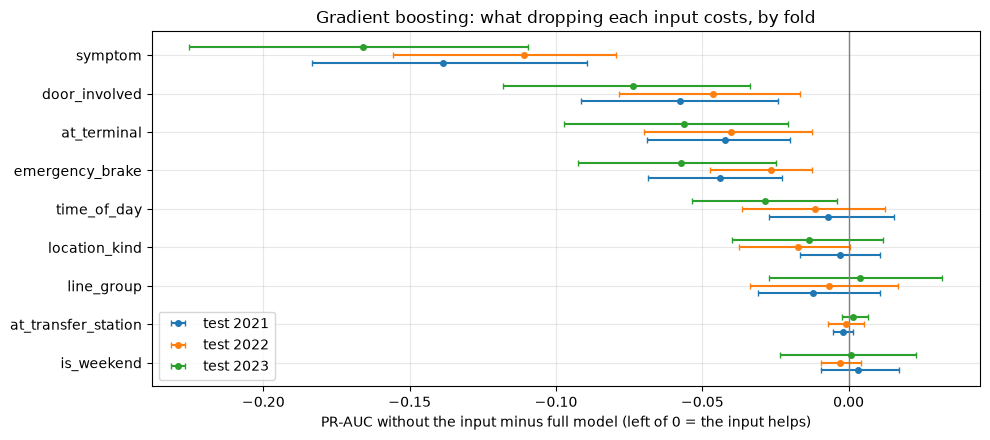

In [9]:
# Plot: PR-AUC change when each input is dropped, with the 95% paired interval per fold.
order = drop_summary.index[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
for offset, (test_year, fold) in zip([-0.2, 0, 0.2], drop_one.groupby("fold")):
    fold = fold.set_index("dropped").loc[order]
    positions = np.arange(len(order)) + offset
    ax.errorbar(fold["pr_auc_difference"], positions,
                xerr=[fold["pr_auc_difference"] - fold["low"], fold["high"] - fold["pr_auc_difference"]],
                fmt="o", markersize=4, capsize=2, label=f"test {test_year}")
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("PR-AUC without the input minus full model (left of 0 = the input helps)")
ax.set_title("Gradient boosting: what dropping each input costs, by fold")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 5. Summary

The three methods agree on the order of the inputs and on which two carry no signal.

| Input | Forest: PR-AUC lost when shuffled | Lasso: enters at C | Gradient boosting: PR-AUC change when dropped (folds clearly worse) | Verdict |
|---|---|---|---|---|
| symptom | 0.148 | 0.003 | −0.139 (3 of 3) | strongest signal |
| door_involved | 0.073 | 0.018 | −0.059 (3 of 3) | strong |
| at_terminal | 0.072 | 0.010 | −0.046 (3 of 3) | strong |
| emergency_brake | 0.059 | 0.032 | −0.043 (3 of 3) | strong |
| time_of_day | 0.009 | 0.018 | −0.016 (1 of 3) | small, helps |
| location_kind | 0.022 | 0.003 | −0.011 (0 of 3) | small, helps |
| line_group | 0.016 | 0.010 | −0.005 (0 of 3) | small |
| is_weekend | −0.001 | 0.562 | +0.000 (0 of 3) | **no signal** |
| at_transfer_station | −0.005 | 1.000 | −0.001 (0 of 3) | **no signal** |

**What this means for the model.**

- **Weekend and transfer station add nothing**: shuffling them costs nothing, the lasso
  keeps them out until the penalty is almost gone, and dropping them changes the
  gradient-boosting PR-AUC by less than 0.001, inside the noise in every fold. They do
  not hurt either: gradient boosting simply rarely splits on them. This is why
  "removing noise" buys nothing here: a tree model already ignores an input with no
  signal.
- **Both are dropped from the main model** (documentation.md, Decision 8): a simpler
  model that scores the same is the better model. They stay in `features.py` as
  `NO_SIGNAL_FEATURES`, so this notebook still runs on the nine original inputs.
- **Importance is not cause.** These numbers say which inputs help *rank* incidents,
  not what *makes* an incident major. Door and emergency-brake incidents are less
  often major (notebook 04) — they carry signal because they mark the routine cases.
